In [3]:
import torch
print("GPU available:", torch.cuda.is_available())


GPU available: True


In [4]:
import kagglehub
path = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
print(path)

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
/kaggle/input/skin-cancer-mnist-ham10000


In [5]:
import os, glob
import pandas as pd

meta = pd.read_csv(os.path.join(path, "HAM10000_metadata.csv"))

files = glob.glob(os.path.join(path, "**", "*.jpg"), recursive=True)
images = {os.path.splitext(os.path.basename(f))[0]: f for f in files}
meta["path"] = meta["image_id"].map(images)

print(meta.shape)
print(meta["dx"].value_counts())
print("Missing image files:", meta["path"].isna().sum())
print("Unique lesions:", meta["lesion_id"].nunique())

(10015, 8)
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64
Missing image files: 0
Unique lesions: 7470


In [6]:
from sklearn.model_selection import StratifiedGroupKFold

classes = sorted(meta["dx"].unique())
meta["label"] = meta["dx"].map({c: i for i, c in enumerate(classes)})
print(classes)

def split(df, n_splits, seed=42):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    a, b = next(sgkf.split(df, df["label"], groups=df["lesion_id"]))
    return df.iloc[a], df.iloc[b]

trainval, test = split(meta, 5)     # 80 / 20
train, val = split(trainval, 8)     # 70 / 10 of the total

print(len(train), len(val), len(test))
print("Lesions shared by train and test:",
      len(set(train["lesion_id"]) & set(test["lesion_id"])))
print(test["dx"].value_counts())

['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
6981 1020 2014
Lesions shared by train and test: 0
dx
nv       1363
mel       222
bkl       205
bcc       100
akiec      68
vasc       34
df         22
Name: count, dtype: int64


In [7]:
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(0.1, 0.1, 0.1),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class SkinDataset(Dataset):
    def __init__(self, df, tf):
        self.df, self.tf = df.reset_index(drop=True), tf
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row["path"]).convert("RGB")
        return self.tf(img), int(row["label"])

train_dl = DataLoader(SkinDataset(train, train_tf), batch_size=32, shuffle=True, num_workers=2)
val_dl = DataLoader(SkinDataset(val, eval_tf), batch_size=64, num_workers=2)
test_dl = DataLoader(SkinDataset(test, eval_tf), batch_size=64, num_workers=2)

x, y = next(iter(train_dl))
print(x.shape, y[:8])

torch.Size([32, 3, 224, 224]) tensor([4, 4, 5, 4, 5, 5, 5, 2])


In [8]:
import numpy as np
import torch.nn as nn
from torchvision import models
from sklearn.metrics import balanced_accuracy_score

device = "cuda"

model = models.efficientnet_b0(weights="IMAGENET1K_V1")
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(classes))
model = model.to(device)

# Rare classes get a bigger weight, so mistakes on them cost more
counts = train["label"].value_counts().sort_index().values
weights = torch.tensor(len(train) / (len(classes) * counts), dtype=torch.float32).to(device)
print(dict(zip(classes, weights.cpu().numpy().round(2))))
criterion = nn.CrossEntropyLoss(weight=weights)

EPOCHS = 10
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 154MB/s]


{'akiec': np.float32(4.17), 'bcc': np.float32(2.79), 'bkl': np.float32(1.28), 'df': np.float32(12.62), 'mel': np.float32(1.32), 'nv': np.float32(0.21), 'vasc': np.float32(10.61)}


In [9]:
def evaluate(dl):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for x, y in dl:
            with torch.autocast("cuda"):
                out = model(x.to(device))
            preds += out.argmax(1).cpu().tolist()
            labels += y.tolist()
    return np.array(labels), np.array(preds)

best = 0.0
for epoch in range(EPOCHS):
    model.train()
    total = 0.0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        with torch.autocast("cuda"):
            loss = criterion(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total += loss.item()
    scheduler.step()

    y_true, y_pred = evaluate(val_dl)
    bal = balanced_accuracy_score(y_true, y_pred)
    acc = (y_true == y_pred).mean()
    print(f"Epoch {epoch+1}: loss={total/len(train_dl):.3f}  "
          f"val_acc={acc:.3f}  val_balanced_acc={bal:.3f}")

    if bal > best:
        best = bal
        torch.save(model.state_dict(), "skin_model.pt")
        print("  saved best model")

Epoch 1: loss=1.191  val_acc=0.599  val_balanced_acc=0.651
  saved best model
Epoch 2: loss=0.725  val_acc=0.635  val_balanced_acc=0.696
  saved best model
Epoch 3: loss=0.583  val_acc=0.701  val_balanced_acc=0.731
  saved best model
Epoch 4: loss=0.461  val_acc=0.768  val_balanced_acc=0.783
  saved best model
Epoch 5: loss=0.366  val_acc=0.756  val_balanced_acc=0.795
  saved best model
Epoch 6: loss=0.297  val_acc=0.770  val_balanced_acc=0.744
Epoch 7: loss=0.239  val_acc=0.769  val_balanced_acc=0.780
Epoch 8: loss=0.212  val_acc=0.784  val_balanced_acc=0.752
Epoch 9: loss=0.179  val_acc=0.778  val_balanced_acc=0.739
Epoch 10: loss=0.189  val_acc=0.791  val_balanced_acc=0.755


Test accuracy: 0.765
Test balanced accuracy: 0.711
              precision    recall  f1-score   support

       akiec       0.42      0.81      0.55        68
         bcc       0.59      0.80      0.68       100
         bkl       0.57      0.57      0.57       205
          df       0.53      0.36      0.43        22
         mel       0.46      0.76      0.58       222
          nv       0.97      0.79      0.87      1363
        vasc       0.65      0.88      0.75        34

    accuracy                           0.76      2014
   macro avg       0.60      0.71      0.63      2014
weighted avg       0.82      0.76      0.78      2014



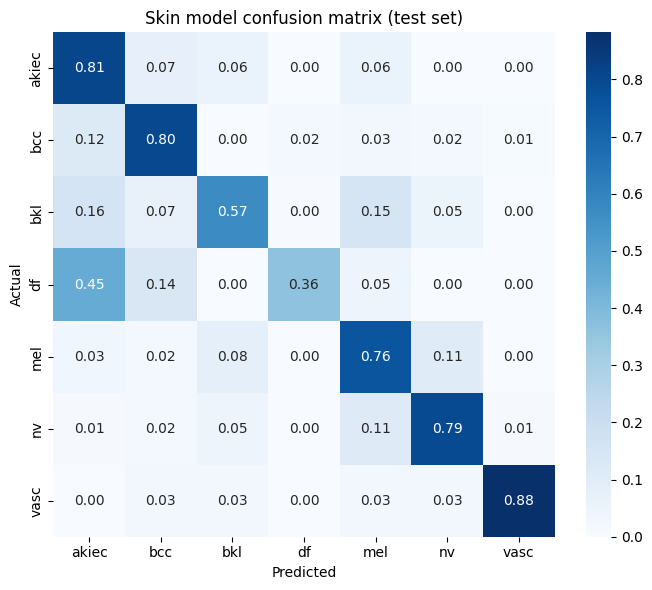

In [10]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

model.load_state_dict(torch.load("skin_model.pt"))
y_true, y_pred = evaluate(test_dl)

print("Test accuracy:", round((y_true == y_pred).mean(), 3))
print("Test balanced accuracy:", round(balanced_accuracy_score(y_true, y_pred), 3))
print(classification_report(y_true, y_pred, target_names=classes))

cm = confusion_matrix(y_true, y_pred, normalize="true")
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Skin model confusion matrix (test set)")
plt.tight_layout()
plt.savefig("skin_confusion_matrix.png", dpi=150)
plt.show()

In [12]:
from google.colab import files
files.download("skin_model.pt")
files.download("skin_confusion_matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>